<a href="https://colab.research.google.com/github/leeale2023/BA305_A9-/blob/main/chocolate_analysis_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chocolate Bar Ratings Analysis
Predicting expert chocolate bar ratings (1–5 scale) from bean origin, manufacturer location, ingredients, cocoa percentage and tasting notes.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import PCA

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

from sklearn.metrics import (mean_squared_error as MSE, mean_absolute_error,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, roc_curve, auc)

url = "https://raw.githubusercontent.com/leeale2023/BA305_A9-/main/chocolate.csv"
choc = pd.read_csv(url)
choc.head()

,ref,company_manufacturer,company_location,review_date,country_of_bean_origin,specific_bean_origin_or_bar_name,cocoa_percent,ingredients,most_memorable_characteristics,rating
0,2454,5150,U.S.A.,2019,Tanzania,"Kokoa Kamili, batch 1",76%,"3- B,S,C","rich cocoa, fatty, bready",3.25
1,2458,5150,U.S.A.,2019,Dominican Republic,"Zorzal, batch 1",76%,"3- B,S,C","cocoa, vegetal, savory",3.50
2,2454,5150,U.S.A.,2019,Madagascar,"Bejofo Estate, batch 1",76%,"3- B,S,C","cocoa, blackberry, full body",3.75
3,2542,5150,U.S.A.,2021,Fiji,"Matasawalevu, batch 1",68%,"3- B,S,C","chewy, off, rubbery",3.00
4,2546,5150,U.S.A.,2021,Venezuela,"Sur del Lago, batch 1",72%,"3- B,S,C","fatty, earthy, moss, nutty,chalky",3.00


## 2. Exploratory analysis
Possible predictive question: which factor of chocolate production drives perceived quality — the origin of the bean, or where/by whom it is manufactured?

Company locations:
 ['U.S.A.' 'France' 'Fiji' 'Vanuatu' 'Ecuador' 'Mexico' 'U.K.'
 'Netherlands' 'Spain' 'Russia' 'Peru' 'Canada' 'Italy' 'Brazil'
 'Nicaragua' 'Australia' 'Philippines' 'Wales' 'Belgium' 'Vietnam'
 'Germany' 'Singapore' 'Switzerland' 'Venezuela' 'Malaysia' 'South Korea'
 'Taiwan' 'Puerto Rico' 'Colombia' 'Japan' 'New Zealand' 'Costa Rica'
 'Hungary' 'Amsterdam' 'Scotland' 'Martinique' 'Sao Tome' 'St. Lucia'
 'Argentina' 'Guatemala' 'South Africa' 'Dominican Republic'
 'Sao Tome & Principe' 'Bolivia' 'Portugal' 'Norway' 'Denmark' 'Grenada'
 'Israel' 'India' 'St.Vincent-Grenadines' 'Czech Republic' 'Thailand'
 'Finland' 'Madagascar' 'Sweden' 'Poland' 'Austria' 'Honduras' 'U.A.E.'
 'Lithuania' 'Ireland' 'Chile' 'Ghana' 'Iceland' 'Suriname' 'El Salvador'] 

Bean origins:
 ['Tanzania' 'Dominican Republic' 'Madagascar' 'Fiji' 'Venezuela' 'Uganda'
 'India' 'Bolivia' 'Peru' 'Panama' 'Colombia' 'Burma' 'Brazil'
 'Papua New Guinea' 'Ecuador' 'Cuba' 'Togo' 'Sao Tome' 'Mexico' 'Va

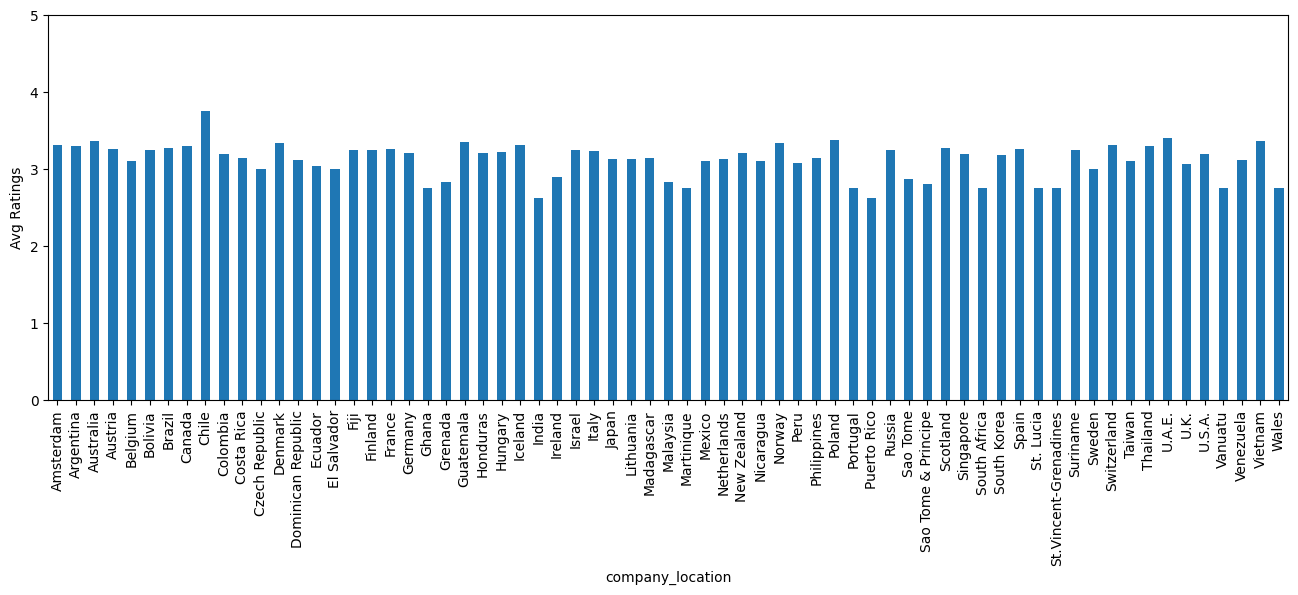

In [2]:
print("Company locations:\n", choc["company_location"].unique(), "\n")
print("Bean origins:\n", choc["country_of_bean_origin"].unique())

ax = choc.groupby("company_location")["rating"].mean().plot(kind="bar", figsize=(16, 5))
ax.set_ylabel("Avg Ratings")
ax.set_ylim(0, 5)
plt.show()

In [30]:
company_location_summary = choc.groupby("company_location")["rating"].agg(["mean", "count"]).sort_values(by="mean", ascending=False)
display(company_location_summary)

,mean,count
company_location,,
Chile,3.750000,2
U.A.E.,3.400000,5
Poland,3.375000,8
Vietnam,3.359375,16
Australia,3.358491,53
...,...,...
South Africa,2.750000,4
Wales,2.750000,1
St.Vincent-Grenadines,2.750000,1


### Tasting-note characteristics
Each review lists comma-separated "most memorable characteristics". We one-hot encode them (stripping whitespace so `" sweet"` and `"sweet"` count as the same word) and look at how often each appears.

In [3]:
chars = choc["most_memorable_characteristics"].str.lower().str.get_dummies(sep=",")
chars.columns = chars.columns.str.strip()
chars = chars.T.groupby(level=0).max().T.astype(int)   # merge columns that only differed by whitespace
chars = chars.loc[:, chars.columns != ""]
print(f"Characteristics feature matrix shape: {chars.shape}")

feature_counts = chars.sum().sort_values(ascending=False)
print("--- Top 30 characteristics ---")
display(feature_counts.head(30))

# Keep characteristics at or above the 90th percentile of frequency (used for PCA below)
q_90 = feature_counts.quantile(0.9)
common_features = feature_counts[feature_counts >= q_90].index
print(f"90th percentile threshold: {q_90} mentions -> {len(common_features)} common characteristics")

Characteristics feature matrix shape: (2530, 966)
--- Top 30 characteristics ---


,0
sweet,273
nutty,261
cocoa,252
roasty,214
earthy,190
creamy,189
sandy,170
fatty,166
floral,146
intense,141


90th percentile threshold: 14.0 mentions -> 101 common characteristics


In [4]:
# Sanity check: do any tasting-note words contain a country/location name?
unique_locations = set(choc["company_location"].dropna()) | set(choc["country_of_bean_origin"].dropna())
exact_matches = unique_locations & set(chars.columns)
partial_matches = [(c, loc) for c in chars.columns for loc in unique_locations
                   if len(loc) > 3 and loc.lower() in c and loc != c]
print(f"Exact matches ({len(exact_matches)}):", exact_matches)
print(f"Partial matches ({len(partial_matches)}):", partial_matches)

Exact matches (0): set()
Partial matches (0): []


### PCA of common sensory characteristics

Number of sensory features used: 101
PC1 explained variance: 0.05514864738287915
PC2 explained variance: 0.04786933858913016
Total explained variance: 0.10301798597200931


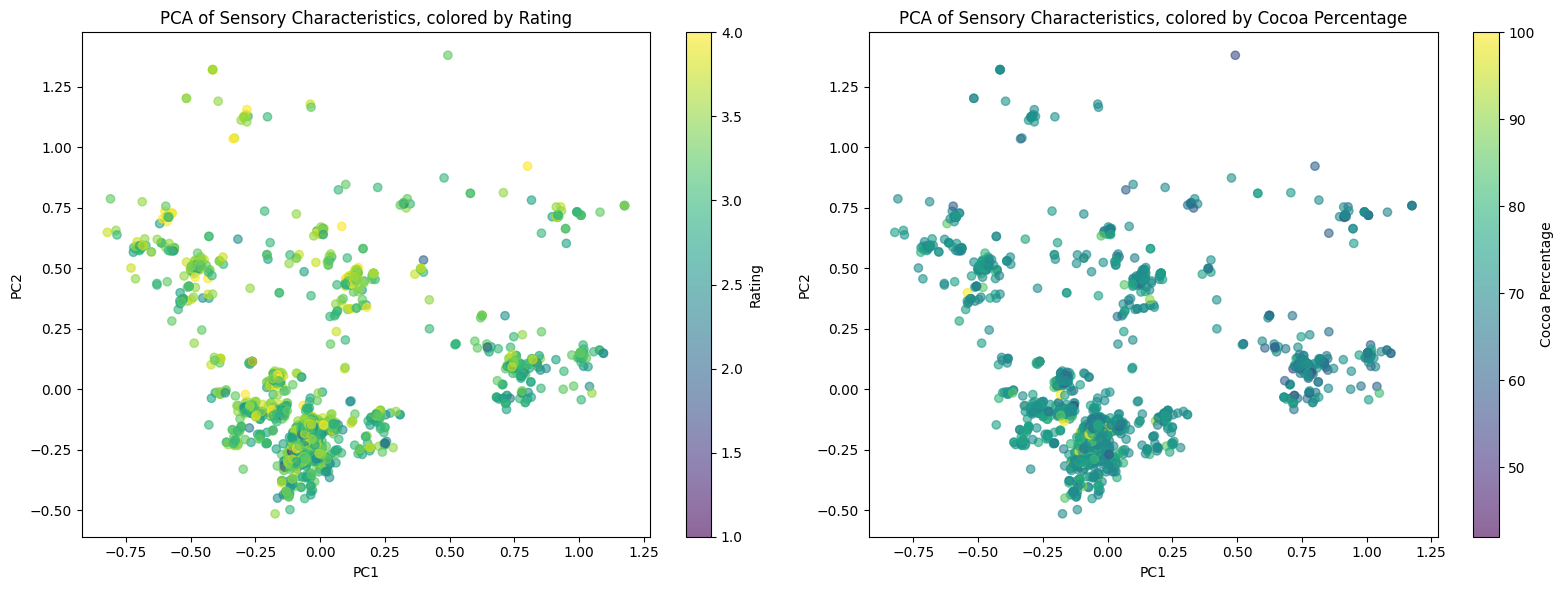

In [5]:
pca = PCA(n_components=2)
pca_df = pd.DataFrame(pca.fit_transform(chars[common_features]), columns=["PC1", "PC2"])

print("Number of sensory features used:", len(common_features))
print("PC1 explained variance:", pca.explained_variance_ratio_[0])
print("PC2 explained variance:", pca.explained_variance_ratio_[1])
print("Total explained variance:", pca.explained_variance_ratio_.sum())

cocoa_for_plot = choc["cocoa_percent"].str.replace("%", "", regex=False).astype(float)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (values, label) in zip(axes, [(choc["rating"], "Rating"), (cocoa_for_plot, "Cocoa Percentage")]):
    sc = ax.scatter(pca_df["PC1"], pca_df["PC2"], c=values, alpha=0.6)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title(f"PCA of Sensory Characteristics, colored by {label}")
    fig.colorbar(sc, ax=ax, label=label)
plt.tight_layout()
plt.show()

## 3. Feature engineering and train/test split
One 70/30 split (`random_state=0`) is used for every model.

`sentiment_total` turns each bar's tasting notes into a single score: a ridge regression learns a score for each word **using training rows only**, and each bar's score is the sum over its characteristics. Because the text split below uses the same `random_state` and length as the feature split, its training rows are exactly the model training rows, so no test ratings leak into the word scores.

In [6]:
y = choc["rating"].values

# Word-level scores, fit on TRAINING descriptions only
C_train, C_test, y_train_c, y_test_c = train_test_split(
    choc["most_memorable_characteristics"], y, test_size=0.3, random_state=0)

vec = CountVectorizer(binary=True, stop_words=["and", "notes", "note", "of", "with", "a", "the"])
ridge_w = RidgeCV(alphas=np.logspace(-2, 3, 30)).fit(vec.fit_transform(C_train), y_train_c)
word_scores = pd.Series(ridge_w.coef_, index=vec.get_feature_names_out())
analyzer = vec.build_analyzer()          # same word-splitting the vectorizer uses

def score_phrase(phrase):
    """Score a phrase: whole phrase if known -> average of its words -> 0."""
    if phrase in word_scores.index:
        return word_scores[phrase]
    words = [word_scores[w] for w in analyzer(phrase) if w in word_scores.index]
    return np.mean(words) if words else 0.0

def sentiment_total(item):
    return sum(score_phrase(c.strip().lower()) for c in item.split(",") if c.strip())

choc["sentiment_total"] = choc["most_memorable_characteristics"].apply(sentiment_total)
choc["cocoa_numeric"] = choc["cocoa_percent"].str.replace("%", "", regex=False).astype(float)
display(choc[["most_memorable_characteristics", "sentiment_total", "rating"]].head())

X = pd.concat([
    pd.get_dummies(choc["country_of_bean_origin"], prefix="origin"),
    pd.get_dummies(choc["company_location"], prefix="location"),
    pd.get_dummies(choc["ingredients"], prefix="ingredients"),
    choc[["cocoa_numeric", "sentiment_total"]]
], axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
assert (X_train.index == C_train.index).all()   # confirms the two splits line up

# Standardized copies for distance/gradient-based models (KNN, neural network)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
print("X shape:", X.shape)

,most_memorable_characteristics,sentiment_total,rating
0,"rich cocoa, fatty, bready",-0.053565,3.25
1,"cocoa, vegetal, savory",0.060984,3.50
2,"cocoa, blackberry, full body",0.440686,3.75
3,"chewy, off, rubbery",-0.587985,3.00
4,"fatty, earthy, moss, nutty,chalky",-0.365433,3.00


X shape: (2530, 152)


## 4. Regression models

### Baseline (predict the mean rating)

In [7]:
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
y_test_pred_dummy = dummy.predict(X_test)
dummy_rmse = np.sqrt(MSE(y_test, y_test_pred_dummy))
dummy_mae = mean_absolute_error(y_test, y_test_pred_dummy)
print(f"Baseline Test RMSE: {dummy_rmse:.3f}")
print(f"Baseline Test MAE: {dummy_mae:.3f}")

Baseline Test RMSE: 0.416
Baseline Test MAE: 0.342


### Linear regression

In [8]:
model = LinearRegression().fit(X_train, y_train)
y_test_pred_lr = model.predict(X_test)
print(f"Training R^2 Score: {model.score(X_train, y_train):.4f}")
print(f"Test R^2 Score: {model.score(X_test, y_test):.4f}")

Training R^2 Score: 0.6078
Test R^2 Score: 0.4184


### K-nearest neighbors

In [9]:
for weight in ["uniform", "distance"]:
    print(f"\nWeighting: {weight}")
    for k in [1, 5, 10, 50, 100]:
        knn = KNeighborsRegressor(n_neighbors=k, weights=weight).fit(X_train_s, y_train)
        rmse_train = np.sqrt(MSE(y_train, knn.predict(X_train_s)))
        rmse_test = np.sqrt(MSE(y_test, knn.predict(X_test_s)))
        rmse_cv = np.sqrt(-cross_val_score(knn, X_train_s, y_train, cv=kfold,
                                           scoring="neg_mean_squared_error").mean())
        print(f"k={k:3d} | train RMSE={rmse_train:.3f} | CV RMSE={rmse_cv:.3f} | test RMSE={rmse_test:.3f}")


Weighting: uniform
k=  1 | train RMSE=0.000 | CV RMSE=0.495 | test RMSE=0.459
k=  5 | train RMSE=0.330 | CV RMSE=0.411 | test RMSE=0.396
k= 10 | train RMSE=0.362 | CV RMSE=0.408 | test RMSE=0.392
k= 50 | train RMSE=0.401 | CV RMSE=0.409 | test RMSE=0.381
k=100 | train RMSE=0.405 | CV RMSE=0.408 | test RMSE=0.379

Weighting: distance
k=  1 | train RMSE=0.000 | CV RMSE=0.495 | test RMSE=0.459
k=  5 | train RMSE=0.000 | CV RMSE=0.413 | test RMSE=0.391
k= 10 | train RMSE=0.000 | CV RMSE=0.404 | test RMSE=0.384
k= 50 | train RMSE=0.000 | CV RMSE=0.400 | test RMSE=0.375
k=100 | train RMSE=0.000 | CV RMSE=0.400 | test RMSE=0.374


In [10]:
# Selected KNN model
best_knn = KNeighborsRegressor(n_neighbors=50, weights="uniform").fit(X_train_s, y_train)
y_test_pred_knn = best_knn.predict(X_test_s)
knn_rmse = np.sqrt(MSE(y_test, y_test_pred_knn))
knn_mae = mean_absolute_error(y_test, y_test_pred_knn)
print(f"KNN Test RMSE: {knn_rmse:.3f}")
print(f"KNN Test MAE: {knn_mae:.3f}")

KNN Test RMSE: 0.381
KNN Test MAE: 0.309


### Decision tree

In [11]:
best_rmse, best_depth, best_leaf = float("inf"), None, None
for depth in [2, 3, 4, 5, 6, 8, 10, 12]:
    for leaf in [1, 2, 5, 10, 20, 30]:
        dt = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=0)
        cv_rmse = np.sqrt(-cross_val_score(dt, X_train, y_train, cv=kfold,
                                           scoring="neg_mean_squared_error").mean())
        print(f"max_depth={depth:2d} | min_samples_leaf={leaf:2d} | CV RMSE={cv_rmse:.3f}")
        if cv_rmse < best_rmse:
            best_rmse, best_depth, best_leaf = cv_rmse, depth, leaf

print(f"\nBest max_depth: {best_depth} | Best min_samples_leaf: {best_leaf} | Best CV RMSE: {best_rmse:.3f}")

max_depth= 2 | min_samples_leaf= 1 | CV RMSE=0.326
max_depth= 2 | min_samples_leaf= 2 | CV RMSE=0.326
max_depth= 2 | min_samples_leaf= 5 | CV RMSE=0.326
max_depth= 2 | min_samples_leaf=10 | CV RMSE=0.326
max_depth= 2 | min_samples_leaf=20 | CV RMSE=0.326
max_depth= 2 | min_samples_leaf=30 | CV RMSE=0.326
max_depth= 3 | min_samples_leaf= 1 | CV RMSE=0.311
max_depth= 3 | min_samples_leaf= 2 | CV RMSE=0.311
max_depth= 3 | min_samples_leaf= 5 | CV RMSE=0.311
max_depth= 3 | min_samples_leaf=10 | CV RMSE=0.313
max_depth= 3 | min_samples_leaf=20 | CV RMSE=0.314
max_depth= 3 | min_samples_leaf=30 | CV RMSE=0.311
max_depth= 4 | min_samples_leaf= 1 | CV RMSE=0.310
max_depth= 4 | min_samples_leaf= 2 | CV RMSE=0.309
max_depth= 4 | min_samples_leaf= 5 | CV RMSE=0.309
max_depth= 4 | min_samples_leaf=10 | CV RMSE=0.315
max_depth= 4 | min_samples_leaf=20 | CV RMSE=0.315
max_depth= 4 | min_samples_leaf=30 | CV RMSE=0.312
max_depth= 5 | min_samples_leaf= 1 | CV RMSE=0.313
max_depth= 5 | min_samples_leaf

In [12]:
# Selected Decision Tree model
best_dt = DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=0).fit(X_train, y_train)
y_test_pred_dt = best_dt.predict(X_test)
test_rmse_dt = np.sqrt(MSE(y_test, y_test_pred_dt))
test_mae_dt = mean_absolute_error(y_test, y_test_pred_dt)
print(f"Train RMSE: {np.sqrt(MSE(y_train, best_dt.predict(X_train))):.3f}")
print(f"Test RMSE: {test_rmse_dt:.3f}")
print(f"Test MAE: {test_mae_dt:.3f}")

feature_importance_dt = pd.Series(best_dt.feature_importances_, index=X.columns).sort_values(ascending=False)
display(feature_importance_dt.head(20))

Train RMSE: 0.286
Test RMSE: 0.316
Test MAE: 0.246


,0
sentiment_total,0.921082
cocoa_numeric,0.053960
"ingredients_3- B,S,C",0.007280
"ingredients_5- B,S,C,V,L",0.004072
origin_Blend,0.003322
location_U.K.,0.002774
location_Canada,0.002219
"ingredients_4- B,S,C,V",0.002073
origin_Vietnam,0.001549
location_U.S.A.,0.001031


The selected tree uses `max_depth=6`, `min_samples_leaf=10` (CV RMSE ≈ 0.317, test RMSE 0.316). Very deep trees with small leaves do worse in CV, so a moderate depth generalizes better. `sentiment_total` accounts for about 92% of the tree's feature importance and cocoa percentage about 5%; geographic and ingredient dummies contribute very little.

### Bagging

In [13]:
bagging_model = BaggingRegressor(random_state=0).fit(X_train, y_train)
y_test_pred_bag = bagging_model.predict(X_test)
test_rmse_bag = np.sqrt(MSE(y_test, y_test_pred_bag))
test_mae_bag = mean_absolute_error(y_test, y_test_pred_bag)
print(f"Train RMSE: {np.sqrt(MSE(y_train, bagging_model.predict(X_train))):.3f}")
print(f"Test RMSE:  {test_rmse_bag:.3f}")
print(f"Test MAE:   {test_mae_bag:.3f}")

Train RMSE: 0.137
Test RMSE:  0.326
Test MAE:   0.259


### Gradient boosting

In [14]:
boosting_model = GradientBoostingRegressor(random_state=0).fit(X_train, y_train)
y_test_pred_boost = boosting_model.predict(X_test)
test_rmse_boost = np.sqrt(MSE(y_test, y_test_pred_boost))
test_mae_boost = mean_absolute_error(y_test, y_test_pred_boost)
print(f"Train RMSE: {np.sqrt(MSE(y_train, boosting_model.predict(X_train))):.3f}")
print(f"Test RMSE:  {test_rmse_boost:.3f}")
print(f"Test MAE:   {test_mae_boost:.3f}")

Train RMSE: 0.264
Test RMSE:  0.303
Test MAE:   0.238


In [15]:
# Tune shrinkage (learning rate), then pruning (ccp_alpha) at the chosen learning rate
grid_lr = GridSearchCV(GradientBoostingRegressor(random_state=0),
                       {"learning_rate": [0.01, 0.05, 0.1, 0.2, 0.3]},
                       scoring="neg_mean_squared_error", cv=kfold, n_jobs=-1).fit(X_train, y_train)
print("--- Learning rate (shrinkage) tuning ---")
for lr, s in zip(grid_lr.cv_results_["param_learning_rate"], grid_lr.cv_results_["mean_test_score"]):
    print(f"learning_rate: {lr:<4} | Mean CV RMSE: {np.sqrt(-s):.4f}")
print("Best learning_rate:", grid_lr.best_params_["learning_rate"])

grid_ccp = GridSearchCV(GradientBoostingRegressor(learning_rate=0.1, random_state=0),
                        {"ccp_alpha": [0.0, 0.0001, 0.001, 0.005, 0.01]},
                        scoring="neg_mean_squared_error", cv=kfold, n_jobs=-1).fit(X_train, y_train)
print("\n--- ccp_alpha (pruning) tuning ---")
for a, s in zip(grid_ccp.cv_results_["param_ccp_alpha"], grid_ccp.cv_results_["mean_test_score"]):
    print(f"ccp_alpha: {a:<6} | Mean CV RMSE: {np.sqrt(-s):.4f}")
print("Best ccp_alpha:", grid_ccp.best_params_["ccp_alpha"])

--- Learning rate (shrinkage) tuning ---
learning_rate: 0.01 | Mean CV RMSE: 0.3297
learning_rate: 0.05 | Mean CV RMSE: 0.2983
learning_rate: 0.1  | Mean CV RMSE: 0.2982
learning_rate: 0.2  | Mean CV RMSE: 0.3026
learning_rate: 0.3  | Mean CV RMSE: 0.3077
Best learning_rate: 0.1

--- ccp_alpha (pruning) tuning ---
ccp_alpha: 0.0    | Mean CV RMSE: 0.2982
ccp_alpha: 0.0001 | Mean CV RMSE: 0.2988
ccp_alpha: 0.001  | Mean CV RMSE: 0.3036
ccp_alpha: 0.005  | Mean CV RMSE: 0.3235
ccp_alpha: 0.01   | Mean CV RMSE: 0.3357
Best ccp_alpha: 0.0


In [16]:
# Bagging vs boosting: 5-fold CV on the training set
for name, m in [("Bagging Regressor", bagging_model), ("Gradient Boosting", boosting_model)]:
    rmse = np.sqrt(-cross_val_score(m, X_train, y_train, cv=kfold,
                                    scoring="neg_mean_squared_error", n_jobs=-1))
    print(f"{name:<18} | Mean CV RMSE: {rmse.mean():.4f} | Std: {rmse.std():.4f}")

Bagging Regressor  | Mean CV RMSE: 0.3216 | Std: 0.0163
Gradient Boosting  | Mean CV RMSE: 0.2978 | Std: 0.0167


,0
sentiment_total,0.856774
cocoa_numeric,0.046560
location_Belgium,0.015178
origin_Blend,0.012931
"ingredients_3- B,S,C",0.010309
"ingredients_2- B,S",0.004698
location_U.K.,0.004402
"ingredients_4- B,S,C,L",0.003944
location_Canada,0.002968
"ingredients_3- B,S,L",0.002826


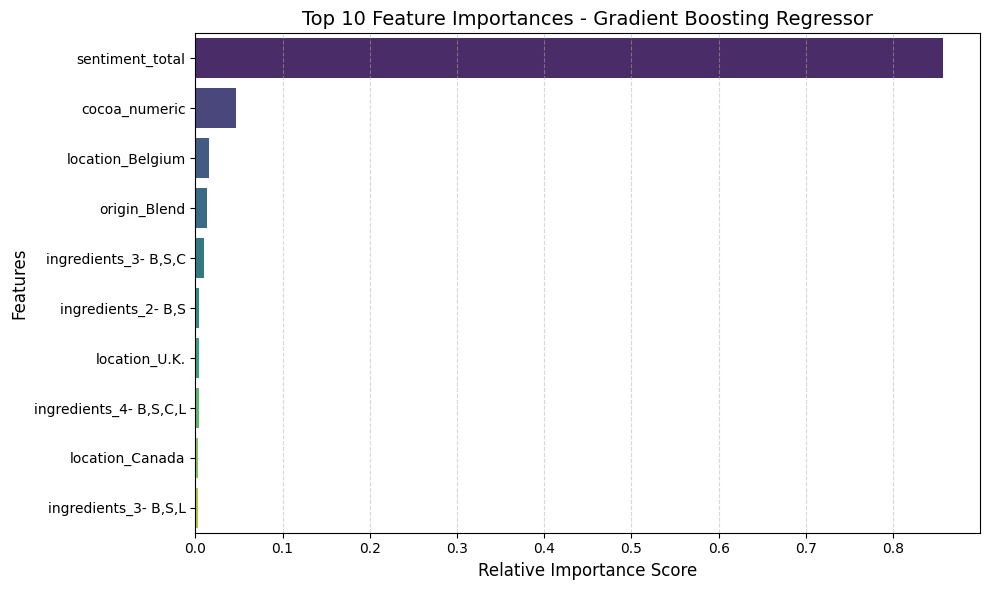

In [17]:
boosting_importances = pd.Series(boosting_model.feature_importances_, index=X.columns).sort_values(ascending=False)
display(boosting_importances.head(20))

top_10 = boosting_importances.head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_10.values, y=top_10.index, palette="viridis", hue=top_10.index, legend=False)
plt.title("Top 10 Feature Importances - Gradient Boosting Regressor", fontsize=14)
plt.xlabel("Relative Importance Score", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Neural network (MLP)

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

# Scale only the continuous columns; leave the 0/1 dummies as they are.
# The scaler sits inside the pipeline, so it is refit within each CV fold.
num_cols = ["cocoa_numeric", "sentiment_total"]
def mlp_pipeline(**params):
    return make_pipeline(
        ColumnTransformer([("num", StandardScaler(), num_cols)], remainder="passthrough"),
        MLPRegressor(max_iter=1000, early_stopping=True, random_state=0, **params))

grid_mlp = GridSearchCV(
    mlp_pipeline(),
    {"mlpregressor__hidden_layer_sizes": [(4,), (8,), (16,), (16, 8)],
     "mlpregressor__alpha": [0.1, 1, 3, 10, 30]},
    scoring="neg_mean_squared_error", cv=kfold, n_jobs=-1).fit(X_train.astype(float), y_train)

print("Best params:", grid_mlp.best_params_)
print(f"Best CV RMSE: {np.sqrt(-grid_mlp.best_score_):.3f}")



Best params: {'mlpregressor__alpha': 10, 'mlpregressor__hidden_layer_sizes': (8,)}
Best CV RMSE: 0.303


In [27]:
# Selected MLP model
mlp_model = grid_mlp.best_estimator_
y_test_pred_mlp = mlp_model.predict(X_test.astype(float))
test_rmse_mlp = np.sqrt(MSE(y_test, y_test_pred_mlp))
test_mae_mlp = mean_absolute_error(y_test, y_test_pred_mlp)
print(f"Test RMSE: {test_rmse_mlp:.3f}")
print(f"Test MAE:  {test_mae_mlp:.3f}")

Test RMSE: 0.307
Test MAE:  0.241


## 5. Model comparison

In [28]:
models_preds = {
    "Baseline Mean": y_test_pred_dummy,
    "Linear Regression": y_test_pred_lr,
    "KNN (k=50)": y_test_pred_knn,
    "Decision Tree": y_test_pred_dt,
    "Bagging Regressor": y_test_pred_bag,
    "Gradient Boosting": y_test_pred_boost,
    "Neural Network (MLP)": y_test_pred_mlp,
}
trained_models = {k: v for k, v in models_preds.items() if k != "Baseline Mean"}

model_comparison = pd.DataFrame({
    "Model": list(models_preds),
    "Test RMSE": [np.sqrt(MSE(y_test, p)) for p in models_preds.values()],
    "Test MAE": [mean_absolute_error(y_test, p) for p in models_preds.values()],
})
display(model_comparison.round(3))

,Model,Test RMSE,Test MAE
0,Baseline Mean,0.416,0.342
1,Linear Regression,0.317,0.246
2,KNN (k=50),0.381,0.309
3,Decision Tree,0.316,0.246
4,Bagging Regressor,0.326,0.259
5,Gradient Boosting,0.303,0.238
6,Neural Network (MLP),0.307,0.241


Gradient Boosting has the lowest test error (RMSE 0.303, MAE 0.238), followed closely by the Decision Tree and Linear Regression (RMSE ≈ 0.316). The tree-based and linear models cut RMSE by roughly 25% versus the mean baseline (0.416). KNN improves only modestly on the baseline, and the neural network did slightly *better* than the decision tree(0.246).

### Error analysis (Decision Tree)

,company_location,country_of_bean_origin,cocoa_percent,ingredients,rating,Predicted,Error,Absolute_Error
883,Switzerland,Blend,62%,"5- B,S,C,V,L",2.00,3.333333,-1.333333,1.333333
2293,U.S.A.,Blend,99%,NaN,3.25,1.933333,1.316667,1.316667
2118,U.S.A.,Ghana,67%,"3- B,S,C",1.50,2.716667,-1.216667,1.216667
1687,U.S.A.,Peru,75%,"3- B,S,C",2.75,3.711039,-0.961039,0.961039
1027,U.S.A.,Peru,70%,"3- B,S,C",2.50,3.406250,-0.906250,0.906250
2456,U.K.,Indonesia,69%,"3- B,S,C",3.75,2.882353,0.867647,0.867647
670,U.S.A.,Liberia,70%,"2- B,S",2.75,3.610947,-0.860947,0.860947
1446,Italy,Ecuador,70%,"4- B,S,C,L",2.00,2.845420,-0.845420,0.845420
1165,Ecuador,Ecuador,80%,"4- B,S,C,L",2.00,2.845420,-0.845420,0.845420
2035,U.S.A.,Blend,82%,"5- B,S,C,V,L",2.00,2.833333,-0.833333,0.833333


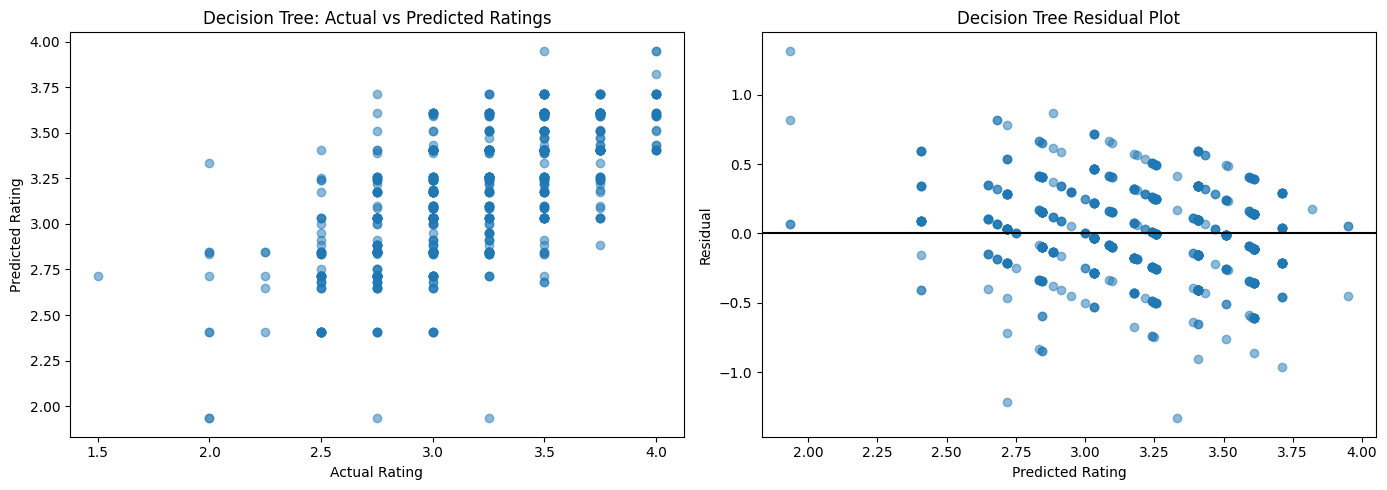

In [29]:
error_details = choc.loc[X_test.index, ["company_location", "country_of_bean_origin",
                                         "cocoa_percent", "ingredients", "rating"]].copy()
error_details["Predicted"] = y_test_pred_dt
error_details["Error"] = error_details["rating"] - error_details["Predicted"]
error_details["Absolute_Error"] = error_details["Error"].abs()
display(error_details.sort_values("Absolute_Error", ascending=False).head(20))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, y_test_pred_dt, alpha=0.5)
axes[0].set_xlabel("Actual Rating")
axes[0].set_ylabel("Predicted Rating")
axes[0].set_title("Decision Tree: Actual vs Predicted Ratings")

axes[1].scatter(y_test_pred_dt, y_test - y_test_pred_dt, alpha=0.5)
axes[1].axhline(0, color="black")
axes[1].set_xlabel("Predicted Rating")
axes[1].set_ylabel("Residual")
axes[1].set_title("Decision Tree Residual Plot")
plt.tight_layout()
plt.show()

## 6. Classification view: is a bar rated ≥ 3.25?
Continuous predictions are turned into a binary "good bar" call to look at precision/recall trade-offs.

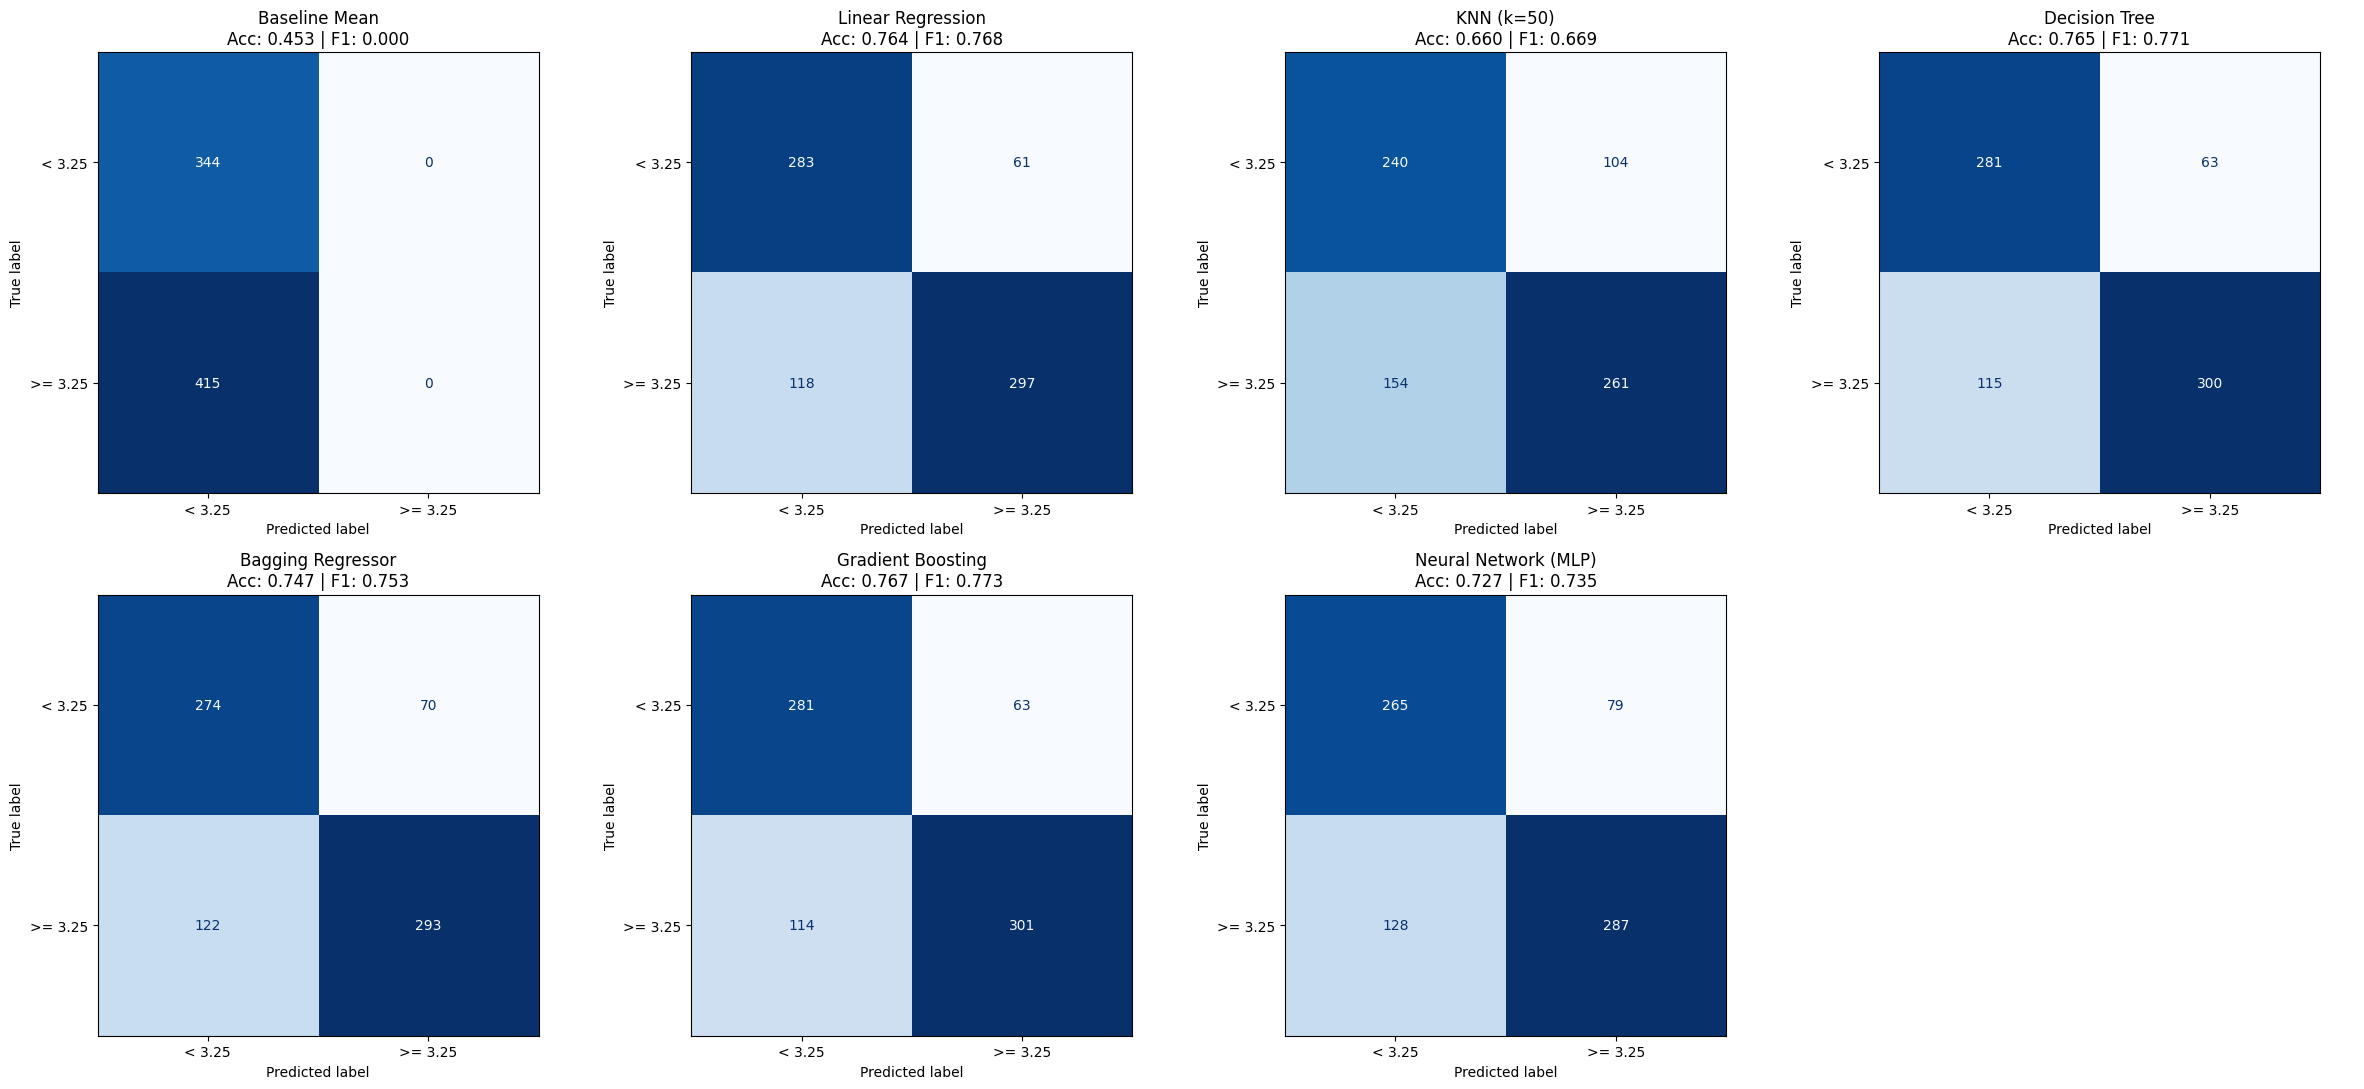

,Model,Accuracy,Precision,Recall,F1-Score,MAE
0,Baseline Mean,0.453,0.000,0.000,0.000,0.342
1,Linear Regression,0.764,0.830,0.716,0.768,0.246
2,KNN (k=50),0.660,0.715,0.629,0.669,0.309
3,Decision Tree,0.765,0.826,0.723,0.771,0.246
4,Bagging Regressor,0.747,0.807,0.706,0.753,0.259
5,Gradient Boosting,0.767,0.827,0.725,0.773,0.238
6,Neural Network (MLP),0.727,0.784,0.692,0.735,0.306


In [22]:
THRESHOLD = 3.25
y_test_binary = (y_test >= THRESHOLD).astype(int)

fig, axes = plt.subplots(2, 4, figsize=(24, 11))
axes = axes.ravel()
metrics_summary = []

for i, (name, preds) in enumerate(models_preds.items()):
    preds_binary = (preds >= THRESHOLD).astype(int)
    acc = (preds_binary == y_test_binary).mean()
    f1 = f1_score(y_test_binary, preds_binary, zero_division=0)
    metrics_summary.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": precision_score(y_test_binary, preds_binary, zero_division=0),
        "Recall": recall_score(y_test_binary, preds_binary, zero_division=0),
        "F1-Score": f1,
        "MAE": mean_absolute_error(y_test, preds),
    })
    ConfusionMatrixDisplay(confusion_matrix(y_test_binary, preds_binary),
                           display_labels=[f"< {THRESHOLD}", f">= {THRESHOLD}"]).plot(
        ax=axes[i], cmap="Blues", colorbar=False)
    axes[i].set_title(f"{name}\nAcc: {acc:.3f} | F1: {f1:.3f}")

for j in range(len(models_preds), len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.show()

display(pd.DataFrame(metrics_summary).round(3))

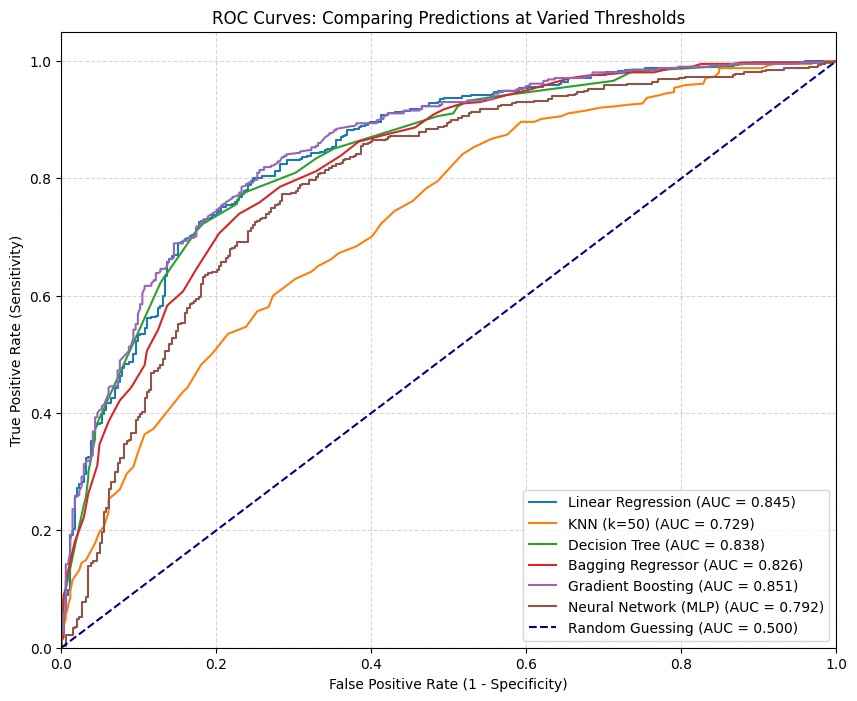

In [23]:
# ROC curves (trained models only)
plt.figure(figsize=(10, 8))
for name, preds in trained_models.items():
    fpr, tpr, _ = roc_curve(y_test_binary, preds)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], color="navy", linestyle="--", label="Random Guessing (AUC = 0.500)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Curves: Comparing Predictions at Varied Thresholds")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

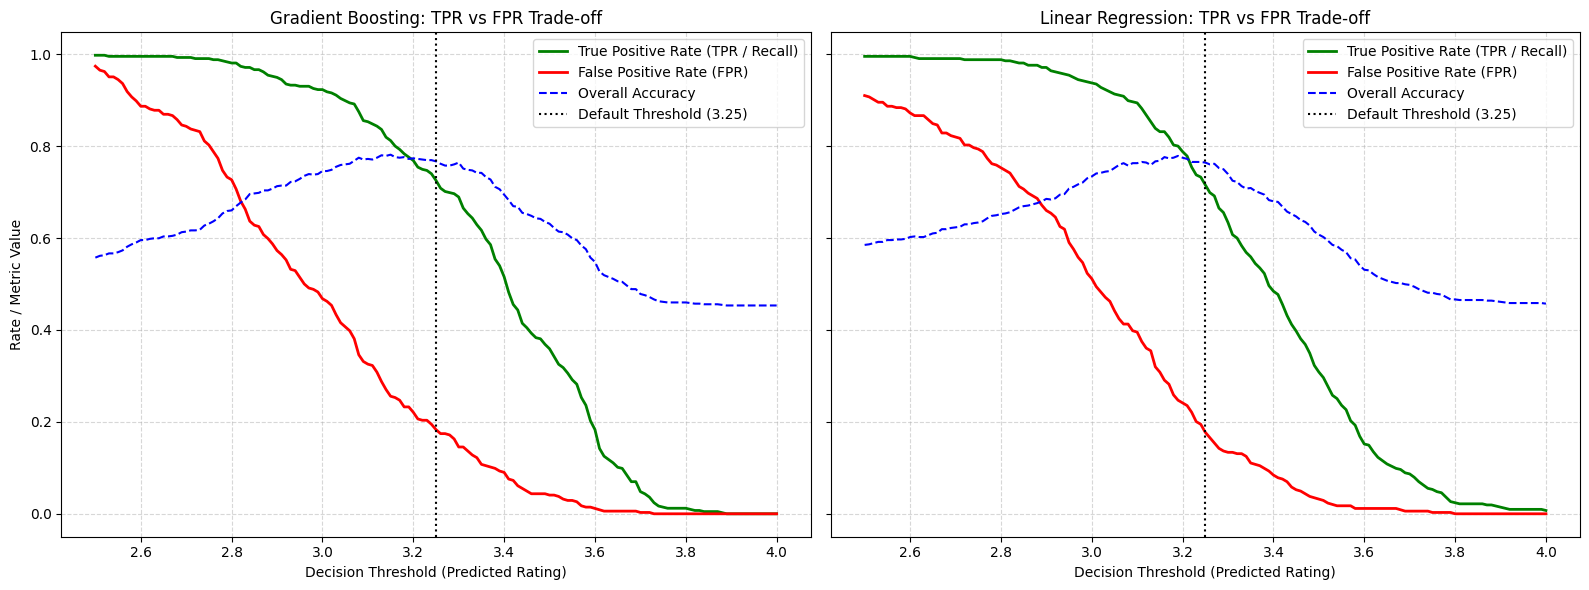

In [24]:
# TPR / FPR / accuracy as the cutoff on PREDICTED rating moves (actual label fixed at >= 3.25)
decision_thresholds = np.arange(2.5, 4.01, 0.01)
threshold_tradeoffs = []
for name, preds in trained_models.items():
    for t in decision_thresholds:
        tn, fp, fn, tp = confusion_matrix(y_test_binary, (preds >= t).astype(int), labels=[0, 1]).ravel()
        threshold_tradeoffs.append({
            "Model": name, "Decision Threshold": t,
            "FPR": fp / (fp + tn) if (fp + tn) else 0.0,
            "TPR": tp / (tp + fn) if (tp + fn) else 0.0,
            "Accuracy": (tp + tn) / (tp + tn + fp + fn),
        })
tradeoff_df = pd.DataFrame(threshold_tradeoffs)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, model_name in zip(axes, ["Gradient Boosting", "Linear Regression"]):
    subset = tradeoff_df[tradeoff_df["Model"] == model_name]
    ax.plot(subset["Decision Threshold"], subset["TPR"], label="True Positive Rate (TPR / Recall)", color="green", lw=2)
    ax.plot(subset["Decision Threshold"], subset["FPR"], label="False Positive Rate (FPR)", color="red", lw=2)
    ax.plot(subset["Decision Threshold"], subset["Accuracy"], label="Overall Accuracy", color="blue", linestyle="--", lw=1.5)
    ax.axvline(THRESHOLD, color="black", linestyle=":", label=f"Default Threshold ({THRESHOLD})")
    ax.set_title(f"{model_name}: TPR vs FPR Trade-off", fontsize=12)
    ax.set_xlabel("Decision Threshold (Predicted Rating)")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="best")
axes[0].set_ylabel("Rate / Metric Value")
plt.tight_layout()
plt.show()

### Threshold sweep from 0 to 1
Ratings (actual and predicted) are rescaled from the 1–5 scale to 0–1 with `(rating − 1) / 4`, so a threshold *t* corresponds to a rating of 1 + 4*t* (e.g. 0.5 → 3.0, 0.6 → 3.4). Note that here the threshold also changes which bars count as "good", so F1 is not directly comparable across thresholds.

,Threshold,Equivalent Rating,Model,Accuracy,Precision,Recall,F1-Score
0,0.0,1.0,Linear Regression,1.000000,1.000000,1.000000,1.000000
1,0.0,1.0,KNN (k=50),1.000000,1.000000,1.000000,1.000000
2,0.0,1.0,Decision Tree,1.000000,1.000000,1.000000,1.000000
3,0.0,1.0,Bagging Regressor,1.000000,1.000000,1.000000,1.000000
4,0.0,1.0,Gradient Boosting,1.000000,1.000000,1.000000,1.000000
5,0.0,1.0,Neural Network (MLP),0.996047,1.000000,0.996047,0.998020
6,0.1,1.4,Linear Regression,1.000000,1.000000,1.000000,1.000000
7,0.1,1.4,KNN (k=50),1.000000,1.000000,1.000000,1.000000
8,0.1,1.4,Decision Tree,1.000000,1.000000,1.000000,1.000000
9,0.1,1.4,Bagging Regressor,1.000000,1.000000,1.000000,1.000000


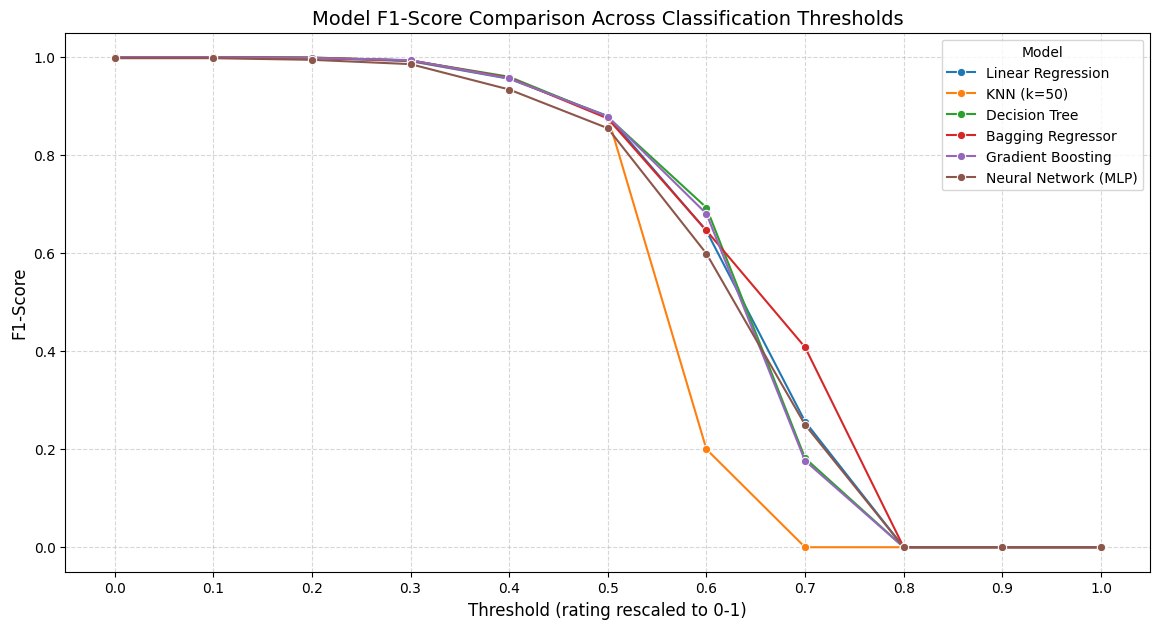

In [25]:
RATING_MIN, RATING_MAX = 1, 5
def to_unit(r):
    return (np.asarray(r) - RATING_MIN) / (RATING_MAX - RATING_MIN)

thresholds = np.round(np.linspace(0, 1, 11), 1)   # 0.0, 0.1, ..., 1.0
y_test_scaled = to_unit(y_test)

threshold_results = []
for t in thresholds:
    y_true_binary = (y_test_scaled >= t).astype(int)
    for name, preds in trained_models.items():
        preds_binary = (to_unit(preds) >= t).astype(int)
        threshold_results.append({
            "Threshold": t,
            "Equivalent Rating": round(RATING_MIN + t * (RATING_MAX - RATING_MIN), 1),
            "Model": name,
            "Accuracy": (preds_binary == y_true_binary).mean(),
            "Precision": precision_score(y_true_binary, preds_binary, zero_division=0),
            "Recall": recall_score(y_true_binary, preds_binary, zero_division=0),
            "F1-Score": f1_score(y_true_binary, preds_binary, zero_division=0),
        })
threshold_df = pd.DataFrame(threshold_results)
with pd.option_context("display.max_rows", 100):
    display(threshold_df)

plt.figure(figsize=(14, 7))
sns.lineplot(data=threshold_df, x="Threshold", y="F1-Score", hue="Model", marker="o")
plt.title("Model F1-Score Comparison Across Classification Thresholds", fontsize=14)
plt.xlabel("Threshold (rating rescaled to 0-1)", fontsize=12)
plt.ylabel("F1-Score", fontsize=12)
plt.xticks(thresholds)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

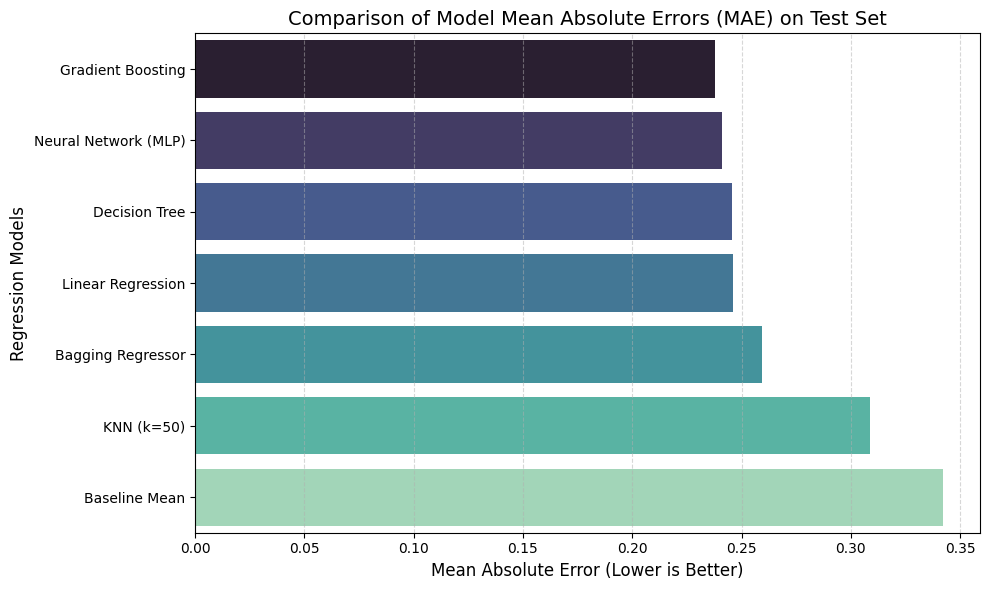

In [31]:
# Categorize models into types for grouping
model_groups = {
    'Baseline Mean': 'Baseline',
    'Linear Regression': 'Linear & Instance',
    'KNN (k=50)': 'Linear & Instance',
    'Decision Tree': 'Trees & Ensembles',
    'Bagging Regressor': 'Trees & Ensembles',
    'Gradient Boosting': 'Trees & Ensembles',
    'Neural Network (MLP)': 'Neural Network'
}

model_comparison['Group'] = model_comparison['Model'].map(model_groups)
plot_data = model_comparison.sort_values(by=['Group', 'Test MAE'])

plt.figure(figsize=(11, 7))
sns.barplot(
    data=plot_data,
    x='Test MAE',
    y='Model',
    hue='Group',
    palette='Set2',
    dodge=False
)
plt.title('Comparison of Model Mean Absolute Errors (MAE) Grouped by Type', fontsize=14, fontweight='bold')
plt.xlabel('Mean Absolute Error (Lower is Better)', fontsize=12)
plt.ylabel('Regression Models', fontsize=12)
plt.legend(title='Model Group', loc='lower right')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()